In [12]:
# Clone the repository and move inside it
!git clone https://github.com/swastiranjan/Geomagnetic-Storm-Prediction.git
%cd Geomagnetic-Storm-Prediction

Cloning into 'Geomagnetic-Storm-Prediction'...
remote: Enumerating objects: 103, done.
remote: Counting objects: 100% (103/103), done.
remote: Compressing objects: 100% (82/82), done.
remote: Total 103 (delta 19), reused 34 (delta 4), pack-reused 0 (from 0)
Receiving objects: 100% (103/103), 9.22 MiB | 4.44 MiB/s, done.
Resolving deltas: 100% (19/19), done.
/content/Geomagnetic-Storm-Prediction/Geomagnetic-Storm-Prediction/Geomagnetic-Storm-Prediction/Geomagnetic-Storm-Prediction


Training HMM...
Model Training Complete. Sequence Log-Likelihood: -13613.69


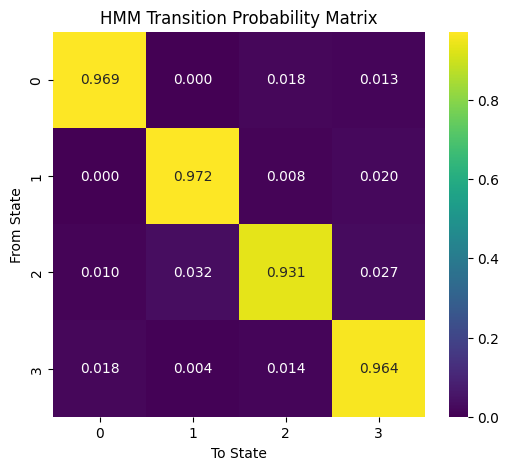

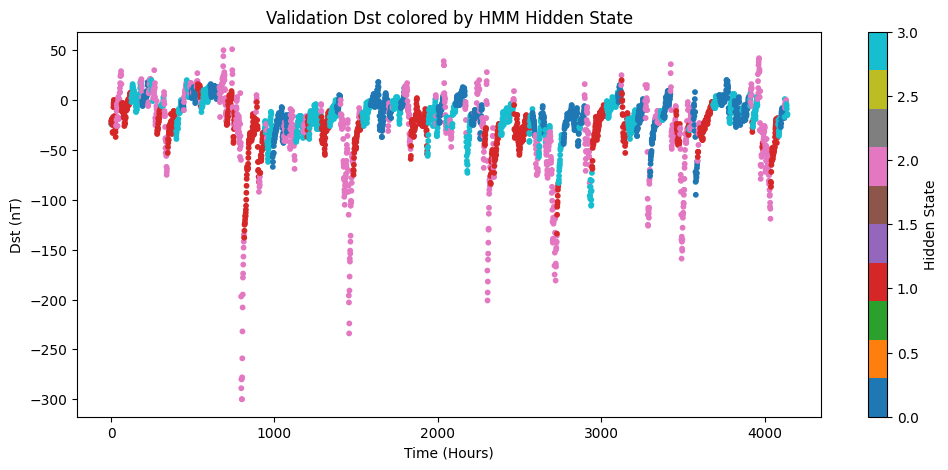

In [13]:
!pip install hmmlearn

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from hmmlearn import hmm
from sklearn.preprocessing import StandardScaler

# 1. Load Data directly from the cloned repo folders
train_df = pd.read_csv("data/processed/train_final.csv")
val_df = pd.read_csv("data/processed/validation_final.csv")

# 2. Select Features
hmm_features = ['bz_gsm_mean', 'speed_mean', 'dynamic_pressure']
X_train = train_df[hmm_features]
X_val = val_df[hmm_features]

# 3. Scale the Data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

# 4. Train the Hidden Markov Model
print("Training HMM...")
model = hmm.GaussianHMM(n_components=4, covariance_type="diag", n_iter=100, random_state=42)
model.fit(X_train_scaled)

# 5. Decode Hidden States & Calculate Likelihood
hidden_states = model.predict(X_val_scaled)
log_likelihood = model.score(X_val_scaled)
print(f"Model Training Complete. Sequence Log-Likelihood: {log_likelihood:.2f}")

# 6. Save Artifacts for Pratistha
os.makedirs("results/hmm", exist_ok=True)

val_df['hidden_state'] = hidden_states
val_df[['period', 'hour', 'dst', 'hidden_state']].to_csv("results/hmm/hmm_decoded_states.csv", index=False)

plt.figure(figsize=(6, 5))
sns.heatmap(model.transmat_, annot=True, cmap='viridis', fmt='.3f')
plt.title('HMM Transition Probability Matrix')
plt.xlabel('To State')
plt.ylabel('From State')
plt.savefig("results/hmm/transition_matrix.png", bbox_inches='tight')
plt.show()

plt.figure(figsize=(12, 5))
scatter = plt.scatter(val_df.index, val_df['dst'], c=val_df['hidden_state'], cmap='tab10', s=10)
plt.colorbar(scatter, label='Hidden State')
plt.title('Validation Dst colored by HMM Hidden State')
plt.xlabel('Time (Hours)')
plt.ylabel('Dst (nT)')
plt.savefig("results/hmm/dst_by_state.png", bbox_inches='tight')
plt.show()

In [14]:
# 1. Calculate and save State Occupancy Counts
occupancy = val_df['hidden_state'].value_counts().sort_index()
occupancy.name = 'Count'
occupancy.index.name = 'Hidden State'
print("--- State Occupancy Counts ---")
print(occupancy)
occupancy.to_csv("results/hmm/state_occupancy.csv")

# 2. Calculate and save State Profiles
profile_cols = ['dst', 'bz_gsm_mean', 'speed_mean', 'dynamic_pressure']
state_profiles = val_df.groupby('hidden_state')[profile_cols].mean()
print("\n--- State Profiles (Means) ---")
print(state_profiles)
state_profiles.to_csv("results/hmm/state_profiles.csv")

print("\nSaved to results/hmm/")

--- State Occupancy Counts ---
Hidden State
0    1033
1    1016
2    1000
3    1092
Name: Count, dtype: int64

--- State Profiles (Means) ---
                    dst  bz_gsm_mean  speed_mean  dynamic_pressure
hidden_state                                                      
0            -11.196515    -0.065116  351.533907          0.825890
1            -29.284449     0.045048  533.615509          1.241226
2            -36.813000    -1.968893  474.276852          3.628030
3            -15.618132    -0.084875  418.666138          1.061696

Saved to results/hmm/
